[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-biopython-course/blob/main/notebooks/06_pairwise_alignment.ipynb)

# 06 · Pairwise Sequence Alignment

*Practical Biopython Course · Hamza Hentabli, Ph.D. · ~50 min*

Comparing two sequences is the most common bioinformatics operation: is this protein related to
that one? Which residues differ? We compare kinase domains from the course panel; how similar the
binding sites are explains why kinase inhibitors so often hit off-targets.

**Learning objectives.** By the end of this notebook you will be able to:

- run global and local alignments with `Bio.Align.PairwiseAligner`
- choose scoring: match/mismatch, substitution matrices (BLOSUM62), and affine gap penalties
- compute percent identity and similarity from an alignment
- build an identity matrix for a panel of drug-target kinases

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'biopython'], check=True)
    if not os.path.isdir("practical-biopython-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-biopython-course.git"], check=True)
    DATA_DIR = "practical-biopython-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. A first alignment

In [2]:
from Bio import Align, SeqIO
from Bio.Align import substitution_matrices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

aligner = Align.PairwiseAligner()
print(aligner)

Pairwise sequence aligner with parameters
  wildcard: None
  match_score: 1.000000
  mismatch_score: 0.000000
  open_internal_insertion_score: -1.000000
  extend_internal_insertion_score: -1.000000
  open_left_insertion_score: -1.000000
  extend_left_insertion_score: -1.000000
  open_right_insertion_score: -1.000000
  extend_right_insertion_score: -1.000000
  open_internal_deletion_score: -1.000000
  extend_internal_deletion_score: -1.000000
  open_left_deletion_score: -1.000000
  extend_left_deletion_score: -1.000000
  open_right_deletion_score: -1.000000
  extend_right_deletion_score: -1.000000
  mode: global



In [3]:
alignments = aligner.align("GAACT", "GAT")
print("score:", alignments.score, "| number of optimal alignments:", len(alignments))
for a in alignments:
    print(a)

score: 1.0 | number of optimal alignments: 2
target            0 GAACT 5
                  0 ||--| 5
query             0 GA--T 3

target            0 GAACT 5
                  0 |-|-| 5
query             0 G-A-T 3



Default scoring is +1 per match, 0 for mismatches and gaps, which gives many equally good alignments.
Realistic protein scoring needs a substitution matrix and gap penalties.

## 2. Substitution matrices

In [4]:
blosum62 = substitution_matrices.load("BLOSUM62")
print("available:", substitution_matrices.load()[:8], "...")
for pair in [("L", "I"), ("L", "L"), ("W", "W"), ("D", "E"), ("W", "G")]:
    print(pair, blosum62[pair])

available: ['BENNER22', 'BENNER6', 'BENNER74', 'BLASTN', 'BLASTP', 'BLOSUM45', 'BLOSUM50', 'BLOSUM62'] ...
('L', 'I') 2.0
('L', 'L') 4.0
('W', 'W') 11.0
('D', 'E') 2.0
('W', 'G') -2.0


BLOSUM62 rewards conservative substitutions (L↔I, D↔E) and penalizes unlikely ones (W↔G). Rare
residues such as W score highly when conserved.

In [5]:
def protein_aligner(mode="global"):
    al = Align.PairwiseAligner()
    al.substitution_matrix = blosum62
    al.open_gap_score = -10       # affine gaps: opening is expensive ...
    al.extend_gap_score = -0.5    # ... extending is cheap (like BLAST/EMBOSS defaults)
    al.mode = mode
    return al

global_al = protein_aligner("global")
local_al = protein_aligner("local")

## 3. EGFR versus HER2 (ERBB2)

In [6]:
domains = {r.id: r.seq for r in SeqIO.parse(f"{DATA_DIR}/sequences/kinase_domains.fasta", "fasta")}
print(list(domains))
aln = global_al.align(domains["EGFR_HUMAN"], domains["ERBB2_HUMAN"])[0]
print("score:", aln.score)
print(aln)

['EGFR_HUMAN', 'ERBB2_HUMAN', 'ERBB3_HUMAN', 'ERBB4_HUMAN', 'EGFR_MOUSE', 'EGFR_DROME', 'LET23_CAEEL', 'ABL1_HUMAN', 'SRC_HUMAN', 'BRAF_HUMAN', 'VGFR2_HUMAN', 'BTK_HUMAN', 'CDK2_HUMAN', 'MET_HUMAN', 'ALK_HUMAN']
score: 1184.0
target            0 FKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDN
                  0 ..|.||||||||||||||.|||.||.||||||||.|||.|||||||||||||||||.|..
query             0 LRKVKVLGSGAFGTVYKGIWIPDGENVKIPVAIKVLRENTSPKANKEILDEAYVMAGVGS

target           60 PHVCRLLGICLTSTVQLITQLMPFGCLLDYVREHKDNIGSQYLLNWCVQIAKGMNYLEDR
                 60 |.|.|||||||||||||.|||||.|||||.|||.....|||.|||||.||||||.||||.
query            60 PYVSRLLGICLTSTVQLVTQLMPYGCLLDHVRENRGRLGSQDLLNWCMQIAKGMSYLEDV

target          120 RLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEYHAEGGKVPIKWMALESILHRIY
                120 |||||||||||||||.|.||||||||||.||...|.||||.|||||||||||||||.|..
query           120 RLVHRDLAARNVLVKSPNHVKITDFGLARLLDIDETEYHADGGKVPIKWMALESILRRRF

target          180 THQSDVWSYGVTVWELMTFGSK

In [7]:
def identity(aln):
    """Percent identity over aligned (non-gap) columns, and over the shorter sequence."""
    c = aln.counts()
    aligned = c.identities + c.mismatches
    shorter = min(len(aln.sequences[0]), len(aln.sequences[1]))
    return 100 * c.identities / aligned, 100 * c.identities / shorter, c

pid_aligned, pid_short, counts = identity(aln)
print(counts)
print(f"identity over aligned columns: {pid_aligned:.1f}%  | over the shorter sequence: {pid_short:.1f}%")

AlignmentCounts object with
    aligned = 268:
        identities = 218,
        mismatches = 50.
    gaps = 0:
        left_gaps = 0:
            left_insertions = 0:
                open_left_insertions = 0,
                extend_left_insertions = 0;
            left_deletions = 0:
                open_left_deletions = 0,
                extend_left_deletions = 0;
        internal_gaps = 0:
            internal_insertions = 0:
                open_internal_insertions = 0,
                extend_internal_insertions = 0;
            internal_deletions = 0:
                open_internal_deletions = 0,
                extend_internal_deletions = 0;
        right_gaps = 0:
            right_insertions = 0:
                open_right_insertions = 0,
                extend_right_insertions = 0;
            right_deletions = 0:
                open_right_deletions = 0,
                extend_right_deletions = 0.

identity over aligned columns: 81.3%  | over the shorter sequence: 81.3%


There is no single definition of "percent identity": always say what the denominator is.

## 4. Global versus local

In [8]:
egfr_full = SeqIO.read(f"{DATA_DIR}/sequences/P00533_EGFR_human.fasta", "fasta").seq
cdk2_kd = domains["CDK2_HUMAN"]
loc = local_al.align(egfr_full, cdk2_kd)[0]
start, end = loc.aligned[0][0][0] + 1, loc.aligned[0][-1][1]
print(f"local alignment of CDK2 kinase domain lands on EGFR residues {start}-{end} (score {loc.score})")
print("EGFR kinase domain per UniProt: 712-979")

local alignment of CDK2 kinase domain lands on EGFR residues 712-965 (score 197.0)
EGFR kinase domain per UniProt: 712-979


**Local** alignment (Smith–Waterman) finds the best-matching region, here the kinase domain inside the
1,210-residue receptor, without being penalized for the unaligned extracellular part. **Global**
alignment (Needleman–Wunsch) forces end-to-end comparison and suits sequences of similar length.

## 5. Spotting a mutation

In [9]:
wt = egfr_full[779:800]                    # residues 780-800
mut = wt[:10] + "M" + wt[11:]              # residue 790: T -> M
a = global_al.align(wt, mut)[0]
print(a)
diff = [i + 780 for i, (x, y) in enumerate(zip(wt, mut)) if x != y]
print("differences at residue(s):", diff, "|", wt[10], "->", mut[10])

target            0 ICLTSTVQLITQLMPFGCLLD 21
                  0 ||||||||||.|||||||||| 21
query             0 ICLTSTVQLIMQLMPFGCLLD 21

differences at residue(s): [790] | T -> M


## 6. An identity matrix for the kinase panel

In [10]:
names = list(domains)
n = len(names)
ident = np.zeros((n, n))
for i in range(n):
    for j in range(i, n):
        a = global_al.align(domains[names[i]], domains[names[j]])[0]
        ident[i, j] = ident[j, i] = identity(a)[0]
ident_df = pd.DataFrame(ident, index=names, columns=names).round(1)
ident_df.loc["EGFR_HUMAN"].sort_values(ascending=False)

EGFR_HUMAN     100.0
EGFR_MOUSE      98.9
ERBB2_HUMAN     81.3
ERBB4_HUMAN     79.1
EGFR_DROME      58.6
ERBB3_HUMAN     58.5
LET23_CAEEL     44.7
ABL1_HUMAN      40.8
MET_HUMAN       40.1
SRC_HUMAN       39.0
VGFR2_HUMAN     38.5
BTK_HUMAN       36.1
ALK_HUMAN       33.8
BRAF_HUMAN      30.8
CDK2_HUMAN      29.7
Name: EGFR_HUMAN, dtype: float64

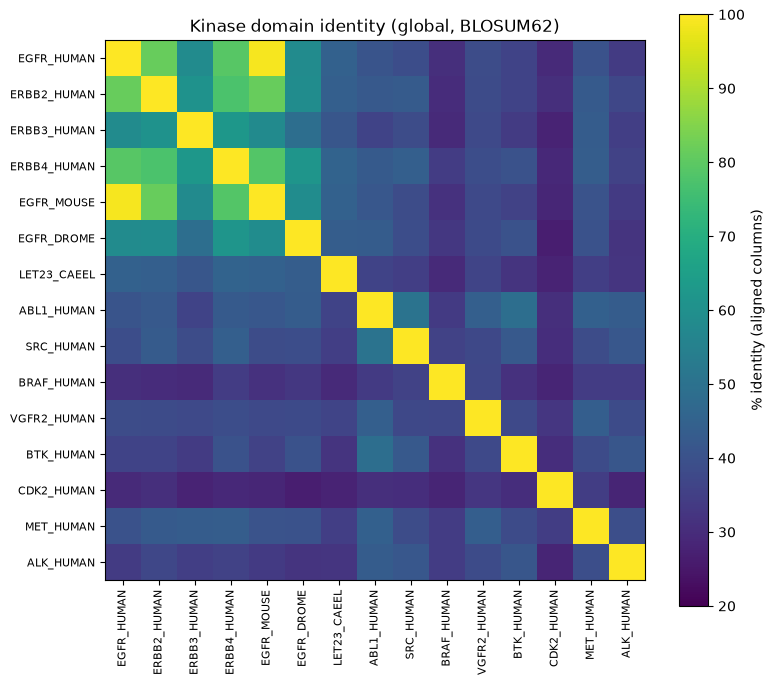

In [11]:
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(ident, cmap="viridis", vmin=20, vmax=100)
ax.set_xticks(range(n)); ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_yticks(range(n)); ax.set_yticklabels(names, fontsize=8)
plt.colorbar(im, label="% identity (aligned columns)")
ax.set_title("Kinase domain identity (global, BLOSUM62)")
plt.tight_layout(); plt.show()

The ErbB family (EGFR, ERBB2/HER2, ERBB4) forms a bright block: drugs designed for EGFR often also
inhibit HER2, which can be desired (lapatinib, a dual EGFR/HER2 inhibitor) or a liability.

### ✏️ Exercise 1

Align the EGFR and ABL1 kinase domains globally, first with the default `protein_aligner`, then with a
much cheaper gap opening (`open_gap_score = -2`). How do the score and the number of gap positions change?

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
a_def = global_al.align(domains["EGFR_HUMAN"], domains["ABL1_HUMAN"])[0]
al = protein_aligner("global")
al.open_gap_score = -2
a_cheap = al.align(domains["EGFR_HUMAN"], domains["ABL1_HUMAN"])[0]
print("open = -10: score", a_def.score, "| gap positions:", a_def.counts().gaps)
print("open =  -2: score", a_cheap.score, "| gap positions:", a_cheap.counts().gaps)
```

</details>

### ✏️ Exercise 2

Which non-ErbB human kinase in the panel is most similar to EGFR's kinase domain? Use `ident_df`.

In [13]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
others = ident_df.loc["EGFR_HUMAN"].drop(["EGFR_HUMAN", "ERBB2_HUMAN", "ERBB3_HUMAN", "ERBB4_HUMAN", "EGFR_MOUSE",
                                         "EGFR_DROME", "LET23_CAEEL"])
print(others.sort_values(ascending=False).head(3))
```

</details>

### ✏️ Exercise 3

Load the PAM250 matrix and re-score EGFR vs ABL1 kinase domains. Is the identity (which does not
depend on the matrix in principle) the same?

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
al = protein_aligner("global")
al.substitution_matrix = substitution_matrices.load("PAM250")
a3 = al.align(domains["EGFR_HUMAN"], domains["ABL1_HUMAN"])[0]
a4 = global_al.align(domains["EGFR_HUMAN"], domains["ABL1_HUMAN"])[0]
print(f"PAM250: {identity(a3)[0]:.1f}%   BLOSUM62: {identity(a4)[0]:.1f}%  (small differences come from different gap placement)")
```

</details>

## Key takeaways

- `PairwiseAligner` does global, local, and semi-global alignment with any scoring scheme.
- Use BLOSUM62 + affine gaps for proteins; state how you computed percent identity.
- Identity matrices of binding domains hint at likely off-targets.

**Next:** [07 · Multiple sequence alignment](07_multiple_sequence_alignment.ipynb).